# Deepelak

Minimal alpr implementation using keras-cv
> inspired from https://keras.io/examples/vision/yolov8/

website: https://deepelak.ir

github: https://github.com/HesamSoleymani/deepelak

In [ ]:
!pip install keras-cv

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 650.7/650.7 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 950.8/950.8 kB 61.1 MB/s eta 0:00:00


#Training
you can skip this part to the [prediction with already trained models](#scrollTo=RSY3H3-5BFmY&line=12&uniqifier=1)

## Dataset
> IR-LPR: Large Scale of Iranian License Plate Recognition Dataset
https://github.com/mut-deep/IR-LPR

Dataset has two part:
* Car Image
<img src="https://github.com/mut-deep/IR-LPR/raw/main/car-image.jpg">
* License plate
<img src="https://github.com/mut-deep/IR-LPR/raw/main/license-plate.jpg">

For each part a model will be trained.

Dataset can be directly downloaded with gdown or be added to google drive

###Option 1: download dataset with gdown

In [ ]:
import zipfile

!pip install -U gdown

!gdown 1ubkg7E2vGEOqS4K_quwf9Vl-i8IVpklM
with zipfile.ZipFile("plate_img-train.zip", 'r') as zip_ref:
    zip_ref.extractall("plate_img-train")


!gdown 1XtZ-XQ8ImNFf40D-bFqTm0UVFqNKhbLi
with zipfile.ZipFile("car_img-train.zip", 'r') as zip_ref:
    zip_ref.extractall("car_img-train")

!gdown 1AL5Zsg2hDqcwF8ZmR0MJTbjgXIoE5W-I
with zipfile.ZipFile("plate_img-validation.zip", 'r') as zip_ref:
    zip_ref.extractall("plate_img-validation")


!gdown 1hwz6X-Zp7JpJL35K6P3z7k6O_PTXhUcT
with zipfile.ZipFile("car_img-validation.zip", 'r') as zip_ref:
    zip_ref.extractall("car_img-validation")

ERROR: Operation cancelled by user
Downloading...
From (original): https://drive.google.com/uc?id=1ubkg7E2vGEOqS4K_quwf9Vl-i8IVpklM
From (redirected): https://drive.google.com/uc?id=1ubkg7E2vGEOqS4K_quwf9Vl-i8IVpklM&confirm=t&uuid=1b8f9f19-c08e-477f-9e2c-c06e6a4610c7
To: /content/plate_img-train.zip
100% 196M/196M [00:05<00:00, 35.4MB/s]


KeyboardInterrupt: 

### Option 2: add dataset to drive and connect drive to colab

1. add dataset to your google drive with "add a shortcut to drive" icon

<img src="https://raw.githubusercontent.com/HesamSoleymani/deepelak/main/static/assets/images/readme/drive.png">

dataset link:
* [car train dataset](https://drive.google.com/file/d/1XtZ-XQ8ImNFf40D-bFqTm0UVFqNKhbLi/view)
* [car validation dataset](https://drive.google.com/file/d/1hwz6X-Zp7JpJL35K6P3z7k6O_PTXhUcT/view)
* [license plate train dataset](https://drive.google.com/file/d/1ubkg7E2vGEOqS4K_quwf9Vl-i8IVpklM/view)
* [license plate validation dataset](https://drive.google.com/file/d/1AL5Zsg2hDqcwF8ZmR0MJTbjgXIoE5W-I/view)


2. connect google drive to colab and unzip dataset using cell below

In [ ]:
from google.colab import drive
import zipfile

drive.mount('/content/drive')
#adjust path according to where you've saved the dataset
path = "./drive/MyDrive/alpr/IR-LPR dataset/";
with zipfile.ZipFile(path + "plate_img-train.zip", 'r') as zip_ref:
    zip_ref.extractall("plate_img-train")
with zipfile.ZipFile(path + "car_img-train.zip", 'r') as zip_ref:
    zip_ref.extractall("car_img-train")
with zipfile.ZipFile(path + "plate_img-validation.zip", 'r') as zip_ref:
    zip_ref.extractall("plate_img-validation")
with zipfile.ZipFile(path + "car_img-validation.zip", 'r') as zip_ref:
    zip_ref.extractall("car_img-validation")

Mounted at /content/drive


##Parse Annotation

In [ ]:
import glob
import xml.etree.ElementTree as ET
import tqdm

class_mapping = {'9': 0, '1': 1, 'و': 2, '2': 3, '6': 4, '7': 5, '8': 6, 'ن': 7, '3': 8, '5': 9, 'م': 10, 'ی': 11, 'ت': 12, 'ل': 13, '4': 14, 'ه\u200d': 15, 'ط': 16, '0': 17, 'د': 18, 'ق': 19, 'ص': 20, 'ب': 21, 'ج': 22, 'س': 23, 'ع': 24, 'ژ (معلولین و جانبازان)': 25, 'الف': 26, 'ز': 27, 'ش': 28, 'پ': 29, 'ث': 30}

def parse_annotation(xml_path, temp_class_mapping, is_car):

    root = ET.parse(xml_path).getroot()
    boxes = []
    classes = []
    for obj in root.findall("object"):
        name = obj.find("name").text.strip()
        if(is_car and name!="کل ناحیه پلاک"):
          continue
        bbox = obj.find("bndbox")
        xmin = int(float(bbox.find("xmin").text))
        ymin = int(float(bbox.find("ymin").text))
        xmax = int(float(bbox.find("xmax").text))
        ymax = int(float(bbox.find("ymax").text))
        boxes.append([xmin, ymin, xmax, ymax])
        if not (name in temp_class_mapping):
          temp_class_mapping[name]=len(temp_class_mapping);
        classes.append(0 if is_car else class_mapping[name]);
    return xml_path.replace(".xml", ".jpg"), boxes, classes

def parse_annotations(dataset_path,class_mapping,is_car):
  xml_files = glob.glob(dataset_path)
  image_paths = []
  bbox = []
  classes = []
  for xml_file in tqdm.tqdm(xml_files):
      image_path, boxes, class_ids = parse_annotation(xml_file, class_mapping,is_car)
      image_paths.append(image_path)
      bbox.append(boxes)
      classes.append(class_ids)
  return image_paths,bbox,classes

car_class_mapping = {}
plate_class_mapping = {}
car_train_data = parse_annotations('./car_img-train/train/*.xml',car_class_mapping,True)
car_val_data = parse_annotations('./car_img-validation/validation/*.xml',car_class_mapping,True)
plate_train_data = parse_annotations('./plate_img-train/train/*.xml',plate_class_mapping,False)
plate_val_data = parse_annotations('./plate_img-validation/validation/*.xml',plate_class_mapping,False)

100%|██████████| 2805/2805 [00:00<00:00, 14514.00it/s]


##Preprocessing and forming final dataset

In [ ]:
import tensorflow as tf
import numpy as np
import keras_cv

BATCH_SIZE = 4

def load_image(image_path):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    return image

def load_dataset(image_path, classes, bbox):
    image = load_image(image_path)
    bounding_boxes = {
        "classes": classes,
        "boxes": bbox,
    }
    return {"images": tf.cast(image, tf.float32), "bounding_boxes": bounding_boxes}

def dict_to_tuple(inputs):
    return inputs["images"], keras_cv.bounding_box.to_dense(
        inputs["bounding_boxes"], max_boxes=32
    )

def make_dataset(image_paths,bbox,classes):
  bbox = tf.ragged.constant(bbox)
  classes = tf.ragged.constant(classes)
  image_paths = tf.ragged.constant(image_paths)
  data = tf.data.Dataset.from_tensor_slices((image_paths, classes, bbox))
  # to be removed
  # data = data.take(10)

  train_ds = data.map(load_dataset)
  train_ds = train_ds.ragged_batch(BATCH_SIZE)
  resizing = keras_cv.layers.Resizing(
      height=640,
      width=640,
      pad_to_aspect_ratio=True,
      bounding_box_format="xyxy"
  )
  train_ds = train_ds.map(resizing)
  train_ds = train_ds.map(dict_to_tuple)
  return train_ds

car_train_ds = make_dataset(*car_train_data)
car_val_ds = make_dataset(*car_val_data)
plate_train_ds = make_dataset(*plate_train_data)
plate_val_ds = make_dataset(*plate_val_data)

SyntaxError: invalid syntax (ipython-input-3714675390.py, line 30)

##Visualization

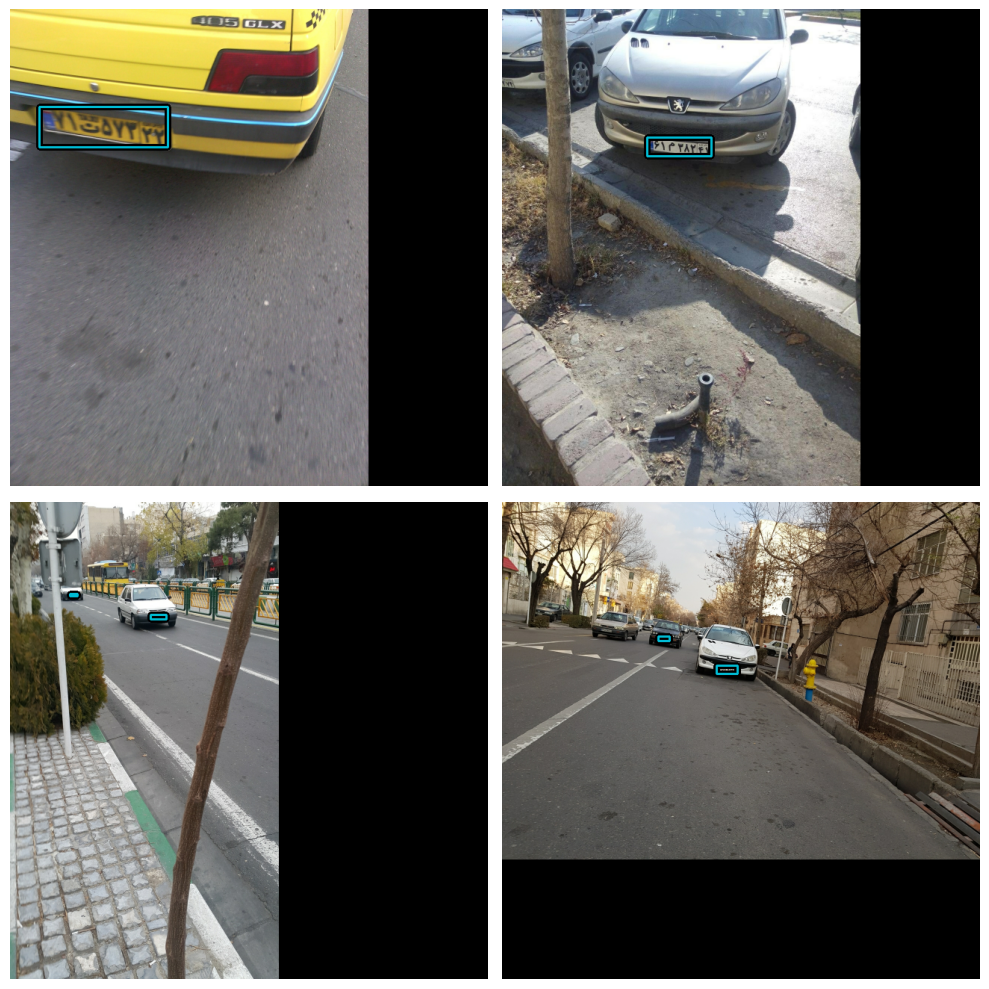

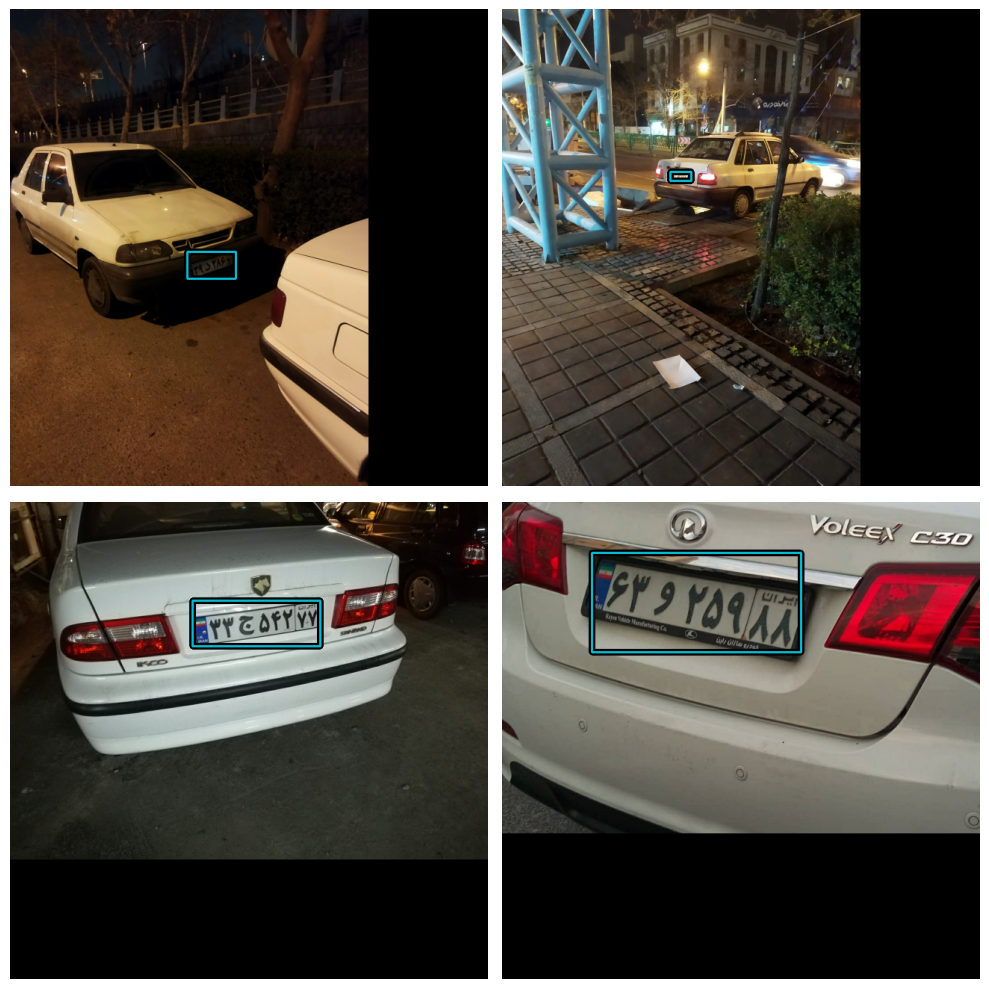

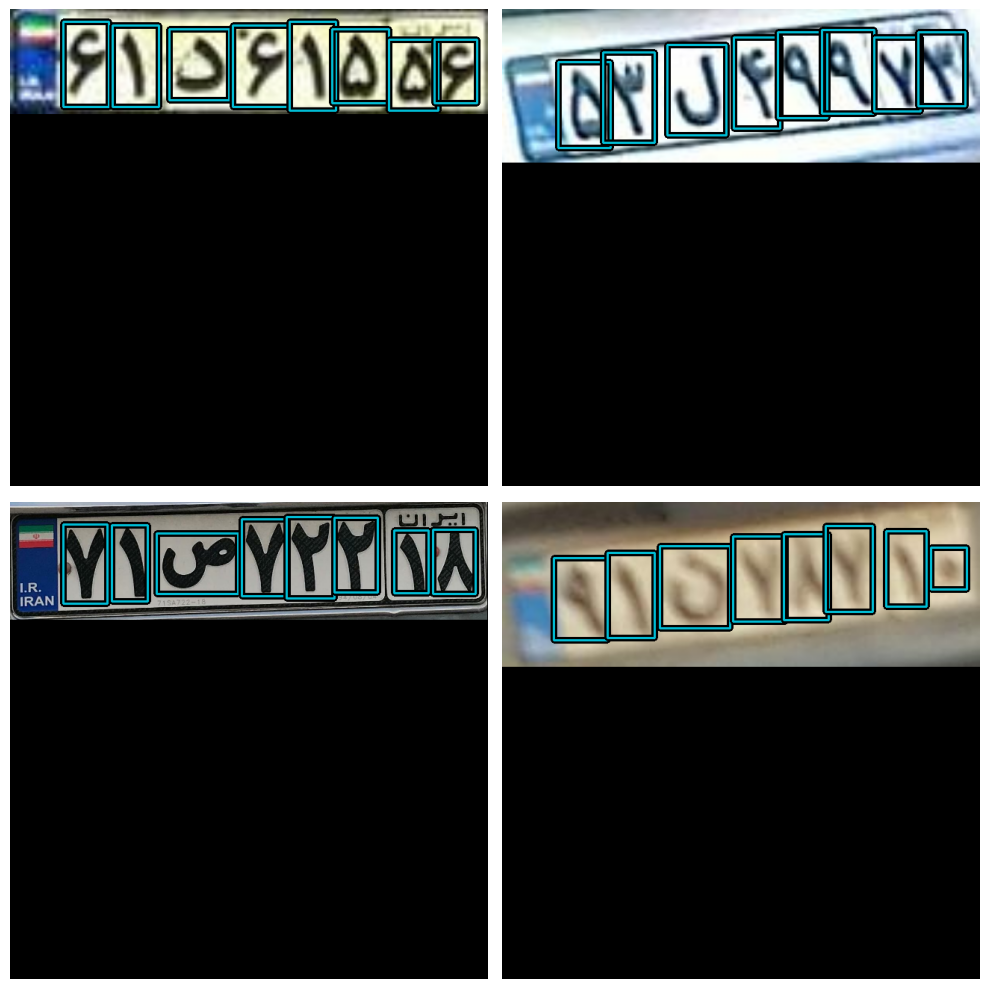

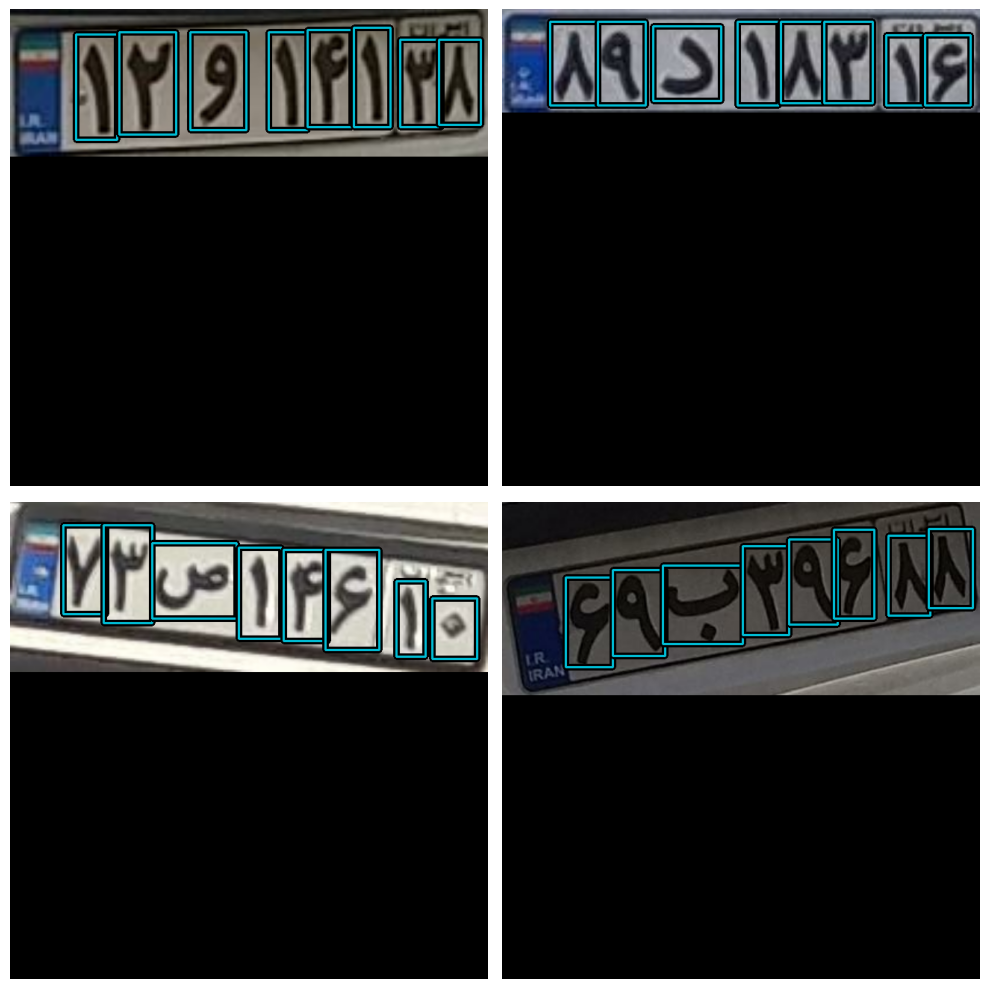

In [ ]:
def visualize_dataset(dataset):
  images, y_true = next(iter(dataset))
  keras_cv.visualization.plot_bounding_box_gallery(
      images=images,
      value_range=(0, 255),
      bounding_box_format="xyxy",
      y_true=y_true,
      rows=2,
      cols=2,
      scale=5,
  )
visualize_dataset(car_train_ds)
visualize_dataset(car_val_ds)
visualize_dataset(plate_train_ds)
visualize_dataset(plate_val_ds)

##Train

###Select backbone and compile models

In [ ]:
import keras_cv
import keras
initial_epoch = 0
detector_learning_rate = 0.001
detector_model_size = "xs"
# can be empty
detector_weight = "_coco"
GLOBAL_CLIPNORM = 10.0
plate_detector = keras_cv.models.YOLOV8Detector(
    num_classes=len(car_class_mapping.keys()),
    bounding_box_format="xyxy",
    backbone=
      keras_cv.models.YOLOV8Backbone.from_preset(
        "yolo_v8_"+detector_model_size+"_backbone"+detector_weight
      ),
    fpn_depth=1,
)
plate_detector.compile(
    optimizer=
      keras.optimizers.Adam(
        learning_rate=detector_learning_rate,
        global_clipnorm=GLOBAL_CLIPNORM,
      ),
    classification_loss="binary_crossentropy", box_loss="ciou",
    jit_compile=False,
)

In [ ]:
import keras_cv
import keras
initial_epoch = 0
recognizer_learning_rate = 0.001
recognizer_model_size = "xs"
# can be empty
recognizer_weight = "_coco"
GLOBAL_CLIPNORM = 10.0
plate_recognizer = keras_cv.models.YOLOV8Detector(
    num_classes=len(plate_class_mapping.keys()),
    bounding_box_format="xyxy",
    backbone=
      keras_cv.models.YOLOV8Backbone.from_preset(
        "yolo_v8_"+recognizer_model_size+"_backbone"+recognizer_weight
      ),
    fpn_depth=1,
)
plate_recognizer.compile(
    optimizer=
      keras.optimizers.Adam(
        learning_rate=recognizer_learning_rate,
        global_clipnorm=GLOBAL_CLIPNORM,
      ),
    classification_loss="binary_crossentropy", box_loss="ciou",jit_compile=False,
)

100%|██████████| 645/645 [00:00<00:00, 1.27MB/s]


###Validation callback

In [ ]:
import os
import tensorflow as tf
from tensorflow import keras

# Assuming keras_cv and other necessary imports are present
# import keras_cv

class EvaluateCOCOMetricsCallback(keras.callbacks.Callback):
    def __init__(self, data, save_path, model_type, model_size, weight, learning_rate):
        super().__init__()
        self.data = data
        self.metrics = keras_cv.metrics.BoxCOCOMetrics(
            bounding_box_format="xyxy",
            evaluate_freq=1e9,
        )

        # The root directory for all saved artifacts
        self.save_root = save_path

        # detector or recognizer
        self.model_type = model_type
        self.model_size = model_size
        self.weight = weight
        self.learning_rate = learning_rate
        self.best_map = -1.0

        # Create the specific directory for this training run
        # This will be the folder that contains all saved models for this run
        self.run_folder_name = f"{self.model_type}_yolov8_{self.model_size}{self.weight}_{self.learning_rate}"
        self.save_path = os.path.join(self.save_root, self.run_folder_name)

        # Create the directory if it doesn't exist
        os.makedirs(self.save_path, exist_ok=True)

    def on_epoch_end(self, epoch, logs):
        self.metrics.reset_state()
        for batch in self.data:
            images, y_true = batch[0], batch[1]
            y_pred = self.model.predict(images, verbose=0)
            self.metrics.update_state(y_true, y_pred)

        metrics = self.metrics.result(force=True)
        logs.update(metrics)

        # Generate the base filename including the epoch, for both model and metrics
        base_filename = f"{self.run_folder_name}_e{epoch+1:04d}"

        # Construct the full paths to save the files directly in the run folder
        model_filename = f"{base_filename}.keras"
        full_model_path = os.path.join(self.save_path, model_filename)

        metrics_filename = f"{base_filename}.txt"
        full_metrics_path = os.path.join(self.save_path, metrics_filename)

        # Save the model
        self.model.save(full_model_path)

        # Save the metrics to a text file
        with open(full_metrics_path, "w") as f:
            f.write(f"Epoch: {epoch+1}\n")
            f.write(f"Name: {base_filename}\n")
            for metric_name, value in logs.items():
                f.write(f"{metric_name}: {value}\n")

        return logs

###(optional) Using Pretrained model to continiue fitting

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

detector_learning_rate = 0.001
detector_model_size = "m"
# can be empty
detector_weight = "_coco"
initial_epoch = 9
GLOBAL_CLIPNORM = 10.0

path = "./drive/MyDrive/alpr/final_models/";
base = f"detector_yolov8_{detector_model_size}{detector_weight}_{str(detector_learning_rate)}"
plate_detector = keras.models.load_model(f"{path}{base}/{base}_e{initial_epoch:04d}.keras", compile=False)
plate_detector.compile(
    optimizer=keras.optimizers.Adam(learning_rate=detector_learning_rate, global_clipnorm=GLOBAL_CLIPNORM),
    classification_loss="binary_crossentropy",
    box_loss="ciou",
    # box_loss_weight=7.5,  # Re-set these attributes
    # classification_loss_weight=0.5, # Re-set these attributes
    jit_compile=False,
)
# plate_recogonizer = keras.models.load_model(path + "plate_model.keras")
# print(type(plate_detector))

KeyboardInterrupt: 

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

recognizer_learning_rate = 0.001
recognizer_model_size = "m"
# can be empty
recognizer_weight = "_coco"
initial_epoch = 6
GLOBAL_CLIPNORM = 10.0

path = "./drive/MyDrive/alpr/final_models/";
print(f"{path}{base}/{base}_e{initial_epoch:04d}.keras")
base = f"recognizer_yolov8_{recognizer_model_size}{recognizer_weight}_{str(recognizer_learning_rate)}"
plate_recognizer = keras.models.load_model(f"{path}{base}/{base}_e{initial_epoch:04d}.keras", compile=False)
plate_recognizer.compile(
    optimizer=keras.optimizers.Adam(learning_rate=recognizer_learning_rate, global_clipnorm=GLOBAL_CLIPNORM),
    classification_loss="binary_crossentropy",
    box_loss="ciou",
    # box_loss_weight=7.5,  # Re-set these attributes
    # classification_loss_weight=0.5, # Re-set these attributes
    jit_compile=False,
)
# plate_recogonizer = keras.models.load_model(path + "plate_model.keras")
# print(type(plate_detector))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
./drive/MyDrive/alpr/final_models/plate_recognizer_m_coco_0.001/plate_recognizer_m_coco_0.001_e0008.keras


###Fit models

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
#adjust path
path = "./drive/MyDrive/alpr/final_models/";

plate_detector.fit(
    car_train_ds,
    initial_epoch=initial_epoch,
    epochs=10,
    callbacks=[EvaluateCOCOMetricsCallback(car_val_ds, path, "detector", detector_model_size, detector_weight, detector_learning_rate)],
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Epoch 1/10
3668/3668 ━━━━━━━━━━━━━━━━━━━━ 1065s 275ms/step - box_loss: 2.5305 - class_loss: 90.6962 - loss: 93.2267 - MaP: 0.5233 - MaP@[IoU=50]: 0.8840 - MaP@[IoU=75]: 0.5868 - MaP@[area=small]: 0.3562 - MaP@[area=medium]: 0.6132 - MaP@[area=large]: 0.5184 - Recall@[max_detections=1]: 0.5437 - Recall@[max_detections=10]: 0.6035 - Recall@[max_detections=100]: 0.6035 - Recall@[area=small]: 0.4804 - Recall@[area=medium]: 0.6875 - Recall@[area=large]: 0.5948
Epoch 2/10
3668/3668 ━━━━━━━━━━━━━━━━━━━━ 1012s 276ms/step - box_loss: 1.2734 - class_loss: 0.7607 - loss: 2.0342 - MaP: 0.6059 - MaP@[IoU=50]: 0.9038 - MaP@[IoU=75]: 0.7168 - MaP@[area=small]: 0.4496 - MaP@[area=medium]: 0.6816 - MaP@[area=large]: 0.6532 - Recall@[max_detections=1]: 0.6176 - Recall@[max_detections=10]: 0.6727 - Recall@[max_detections=100]: 0.6727 - Recall@[area=small]: 0.5456 - Recall@[area

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
#adjust path
path = "./drive/MyDrive/alpr/final_models/";

plate_recognizer.fit(
    plate_train_ds,
    initial_epoch=initial_epoch,
    epochs=10,
    callbacks=[EvaluateCOCOMetricsCallback(plate_val_ds, path ,"recognizer",recognizer_model_size,recognizer_weight, recognizer_learning_rate)],
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Epoch 9/10
4846/4846 ━━━━━━━━━━━━━━━━━━━━ 2718s 550ms/step - box_loss: 0.8032 - class_loss: 0.0114 - loss: 0.8146 - MaP: 0.6069 - MaP@[IoU=50]: 0.8426 - MaP@[IoU=75]: 0.7203 - MaP@[area=small]: 0.0000e+00 - MaP@[area=medium]: 0.6945 - MaP@[area=large]: 0.5915 - Recall@[max_detections=1]: 0.5893 - Recall@[max_detections=10]: 0.6573 - Recall@[max_detections=100]: 0.6573 - Recall@[area=small]: 0.0000e+00 - Recall@[area=medium]: 0.7275 - Recall@[area=large]: 0.6547
Epoch 10/10
4846/4846 ━━━━━━━━━━━━━━━━━━━━ 2720s 549ms/step - box_loss: 0.7804 - class_loss: 0.0111 - loss: 0.7916 - MaP: 0.6298 - MaP@[IoU=50]: 0.8331 - MaP@[IoU=75]: 0.7446 - MaP@[area=small]: 0.0000e+00 - MaP@[area=medium]: 0.7485 - MaP@[area=large]: 0.5990 - Recall@[max_detections=1]: 0.6080 - Recall@[max_detections=10]: 0.6775 - Recall@[max_detections=100]: 0.6775 - Recall@[area=small]: 0.0000e+00

#Prediction

> ***important!: for prediction part, change runtime from gpu to cpu (TODO: find and fix gpu problem, probably related to Non-Max Suppression)***

## Option 1: using trained models from previous steps

##Option 2: loading pretrained models from google drive

1. add dataset to your google drive with "add a shortcut to drive" icon

<img src="https://raw.githubusercontent.com/HesamSoleymani/deepelak/main/static/assets/images/readme/drive.png">

models link:
* [plate detector model](https://drive.google.com/file/d/1aINiD-6AjmpQQ1SIJytW5i7g1yOlvp7N/view)
* [plate recogonizer model](https://drive.google.com/file/d/1Jh7cD-5_25DP7yB3o2fB7DhhCghCc-5X/view)


2. connect google drive to colab and unzip dataset using cell below

In [ ]:
from google.colab import drive
import keras

!pip install keras-cv

drive.mount('/content/drive')
#adjust path according to where you've saved the dataset
path = "./drive/MyDrive/alpr/final_models/";
plate_detector = keras.models.load_model(path + "car_model.keras")
plate_recogonizer = keras.models.load_model(path + "plate_model.keras")

class_mapping = {0: '9',
 1: '1',
 2: 'و',
 3: '2',
 4: '6',
 5: '7',
 6: '8',
 7: 'ن',
 8: '3',
 9: '5',
 10: 'م',
 11: 'ی',
 12: 'ت',
 13: 'ل',
 14: '4',
 15: 'ه\u200d',
 16: 'ط',
 17: '0',
 18: 'د',
 19: 'ق',
 20: 'ص',
 21: 'ب',
 22: 'ج',
 23: 'س',
 24: 'ع',
 25: 'ژ (معلولین و جانبازان)',
 26: 'الف',
 27: 'ز',
 28: 'ش',
 29: 'پ',
 30: 'ث'}

## Upload car image

In [ ]:
from google.colab import files
uploaded = files.upload()
image_name = list(uploaded.keys())[0]

Saving 157134684 (1).jpg to 157134684 (1).jpg


## Visualize prediction and text extraction

/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor']
Received: inputs=Tensor(shape=(1, 640, 640, 3))
  warnings.warn(msg)


1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step


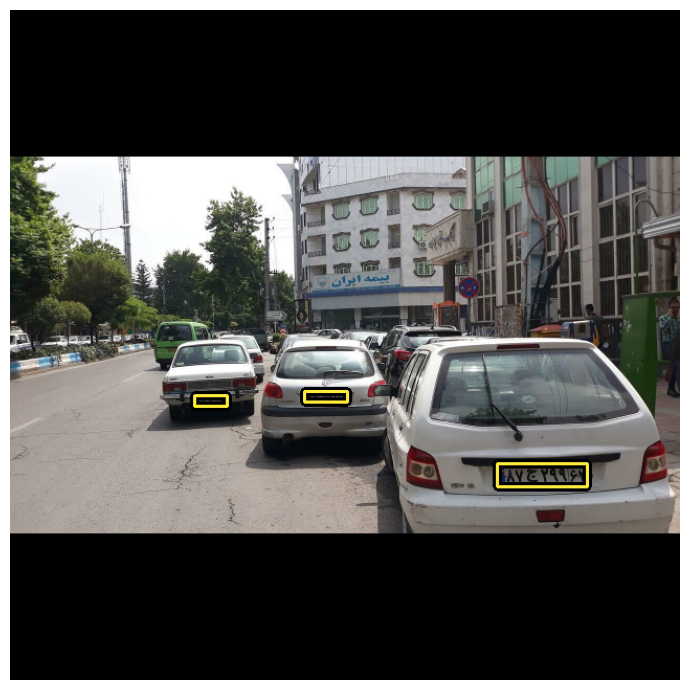

/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_295']
Received: inputs=Tensor(shape=(1, 640, 640, 3))
  warnings.warn(msg)


1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step


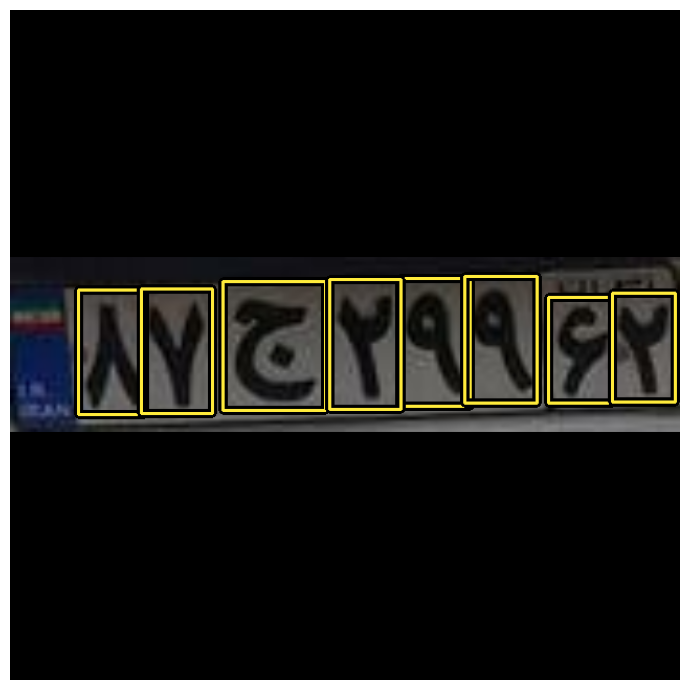

8
7
ج
2
9
9
6
2
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 966ms/step


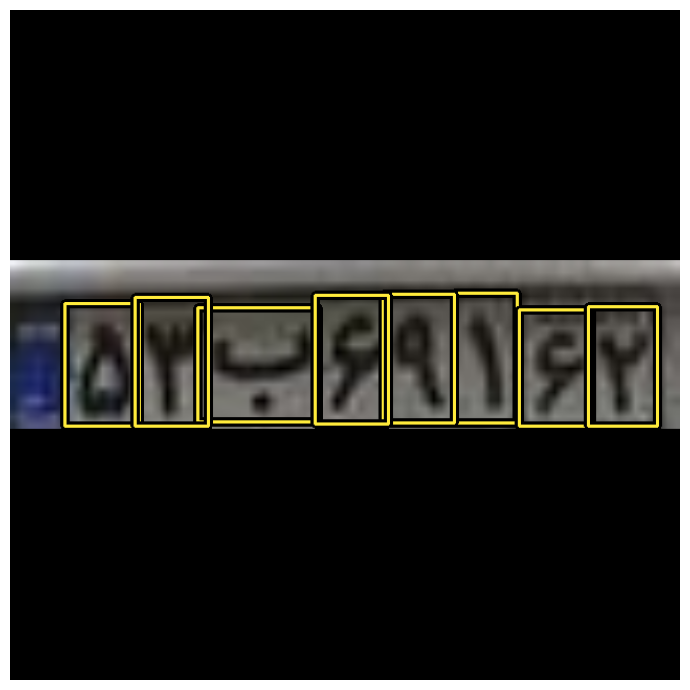

5
3
ب
6
9
1
6
2
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


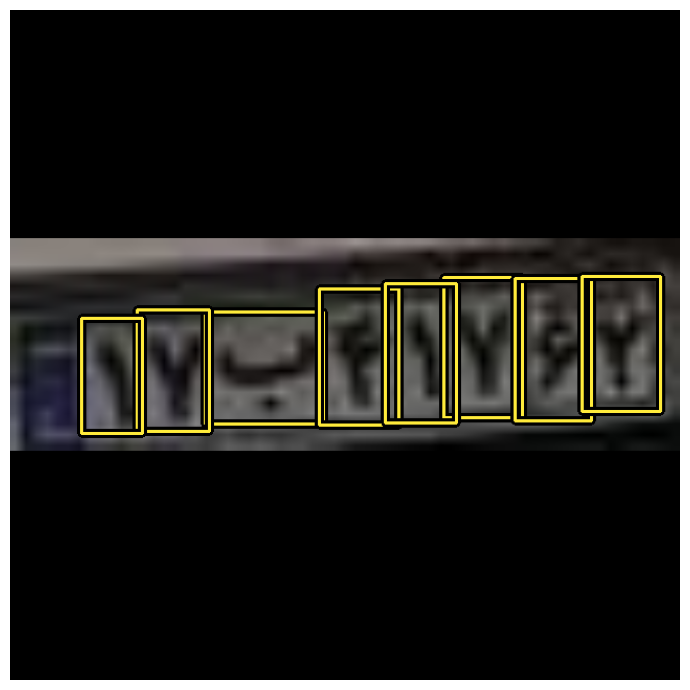

1
7
ب
4
1
7
6
2


In [ ]:
import numpy as np
import tensorflow as tf
import keras_cv
import matplotlib.pyplot as plt
import io

def extract_license_text(prediction):
    boxes = prediction['boxes'][0]
    classes = prediction['classes'][0]
    confidences = prediction['confidence'][0]
    num_detections = prediction['num_detections'][0]
    char_boxes = []
    for i in range(num_detections):
        if classes[i] < 0 or confidences[i] < 0:
            continue
        char_box = boxes[i]
        char_boxes.append((char_box,classes[i]))
    char_boxes.sort(key=lambda x: x[0][0])
    chars = [class_mapping[c] for _, c in char_boxes]
    for c in chars:
        print(c)

image = tf.io.read_file(image_name)
image = tf.image.decode_jpeg(image, channels=3)

h = image.shape[0]
w = image.shape[1]
if(h>w):
  w1 = w * 640 / h
  h1 = 640
else:
  h1 = h * 640 / w
  w1 = 640

resized_image = tf.image.resize_with_pad(image, target_height=640, target_width=640)
plate_pred = plate_detector.predict(np.array([resized_image]))

conf = plate_pred["confidence"][0]
boxes = plate_pred["boxes"][0]
classes = plate_pred["classes"][0]

conf_threshold = 0.5
valid_count = 0
for i in range(len(conf)):
    if conf[i] < conf_threshold:
      conf[i] = -1
      classes[i] = -1
      boxes[i] = [-1, -1, -1, -1]
    else:
      valid_count += 1

plate_pred["num_detections"][0] = valid_count

keras_cv.visualization.plot_bounding_box_gallery(
    images=np.array([resized_image]),
    value_range=(0, 255),
    bounding_box_format="xyxy",
    y_pred=plate_pred,
    scale=7,
    rows=1,
    cols=1,
    show=True,
    font_scale=0.7,
)

for i in range(plate_pred["num_detections"][0]):
  box = plate_pred["boxes"][0][i]
  x1 = int((box[0] - (640 - w1) / 2) * max(w,h)/640)
  x2 = int((box[2] - (640 - w1) / 2) * max(w,h)/640)
  y1 = int((box[1] - (640 - h1) / 2) * max(w,h)/640)
  y2 = int((box[3] - (640 - h1) / 2) * max(w,h)/640)
  plate = image[y1:y2, x1:x2]
  plate = tf.image.resize_with_pad(plate, target_height=640, target_width=640)


  y_pred = plate_recogonizer.predict(np.array([plate]))

  keras_cv.visualization.plot_bounding_box_gallery(
      images=np.array([plate]),
      value_range=(0, 255),
      bounding_box_format="xyxy",
      y_pred=y_pred,
      scale=7,
      rows=1,
      cols=1,
      show=True,
      font_scale=0.7,
  )

  extract_license_text(y_pred)